In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


In [3]:
df = pd.read_csv('/content/drive/MyDrive/DQlab bnsp/Project/Irrigation prediction.csv')

In [4]:
df.head(10)

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium
5,Silt,5.10,20.50,0.37,1.43,33.34,62.51,402.92,7.03,13.55,Rice,Sowing,Zaid,Sprinkler,Groundwater,7.56,Yes,7.33,East,Medium
6,Sandy,7.44,22.70,0.59,2.95,28.02,58.50,764.95,7.08,7.38,Rice,Flowering,Kharif,Sprinkler,Reservoir,2.18,No,51.47,West,Medium
7,Sandy,7.68,40.23,0.62,3.30,35.60,79.10,833.33,5.17,3.73,Wheat,Vegetative,Zaid,Rainfed,Reservoir,12.54,Yes,118.96,West,Low
8,Clay,5.42,36.73,0.74,1.52,16.59,76.88,2476.03,10.34,1.80,Maize,Flowering,Kharif,Sprinkler,Rainwater,13.75,Yes,107.25,Central,Low
9,Loamy,6.26,19.58,0.36,1.67,31.14,74.30,1474.55,8.53,17.68,Rice,Vegetative,Rabi,Rainfed,Reservoir,1.27,Yes,97.92,Central,Medium


In [5]:
# Informasi tipe data dan jumlah data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Soil_Type                10000 non-null  object 
 1   Soil_pH                  10000 non-null  float64
 2   Soil_Moisture            10000 non-null  float64
 3   Organic_Carbon           10000 non-null  float64
 4   Electrical_Conductivity  10000 non-null  float64
 5   Temperature_C            10000 non-null  float64
 6   Humidity                 10000 non-null  float64
 7   Rainfall_mm              10000 non-null  float64
 8   Sunlight_Hours           10000 non-null  float64
 9   Wind_Speed_kmh           10000 non-null  float64
 10  Crop_Type                10000 non-null  object 
 11  Crop_Growth_Stage        10000 non-null  object 
 12  Season                   10000 non-null  object 
 13  Irrigation_Type          10000 non-null  object 
 14  Water_Source           

In [6]:
df.describe()

,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Field_Area_hectare,Previous_Irrigation_mm
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,6.487857,36.969207,0.944731,1.791963,26.991423,60.080339,1252.499420,7.518538,10.163545,7.598024,59.864122
std,0.979963,16.430845,0.372406,0.984202,8.664074,20.187973,715.582201,2.016077,5.670923,4.233919,34.483722
min,4.800000,8.000000,0.300000,0.100000,12.000000,25.000000,0.380000,4.000000,0.500000,0.300000,0.020000
25%,5.640000,22.860000,0.620000,0.940000,19.460000,42.855000,634.155000,5.760000,5.160000,3.950000,30.160000
50%,6.470000,37.240000,0.950000,1.780000,27.090000,60.040000,1250.335000,7.560000,10.190000,7.540000,59.630000
75%,7.350000,50.940000,1.260000,2.650000,34.500000,77.705000,1880.265000,9.260000,15.100000,11.202500,90.030000
max,8.200000,65.000000,1.600000,3.500000,42.000000,95.000000,2499.690000,11.000000,20.000000,15.000000,119.990000


In [7]:
# Jumlah missing values
print("\nMissing values:")
print(df.isnull().sum())

# Jumlah data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())


Missing values:
Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64

Jumlah data duplikat: 0


Irrigation_Need
Low       5864
Medium    3800
High       336
Name: count, dtype: int64


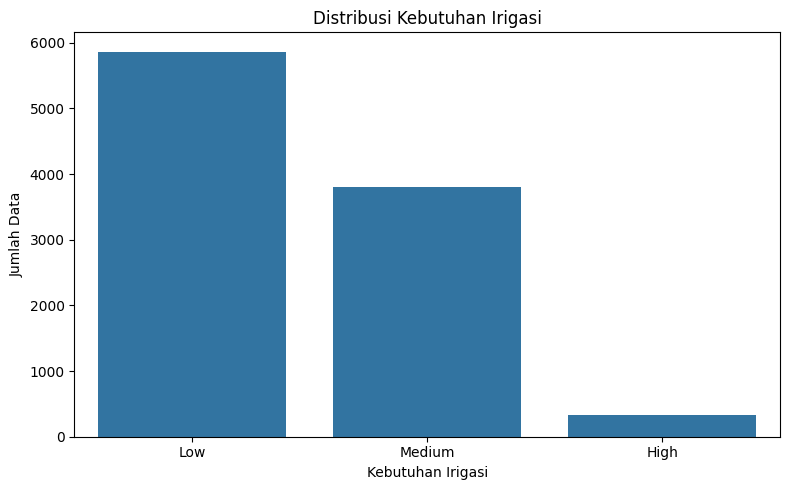

In [8]:
target = "Irrigation_Need"

if target not in df.columns:
    raise ValueError(
        f"Kolom target '{target}' tidak ditemukan. "
        f"Kolom tersedia: {df.columns.tolist()}"
    )

print(df[target].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=target)
plt.title("Distribusi Kebutuhan Irigasi")
plt.xlabel("Kebutuhan Irigasi")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

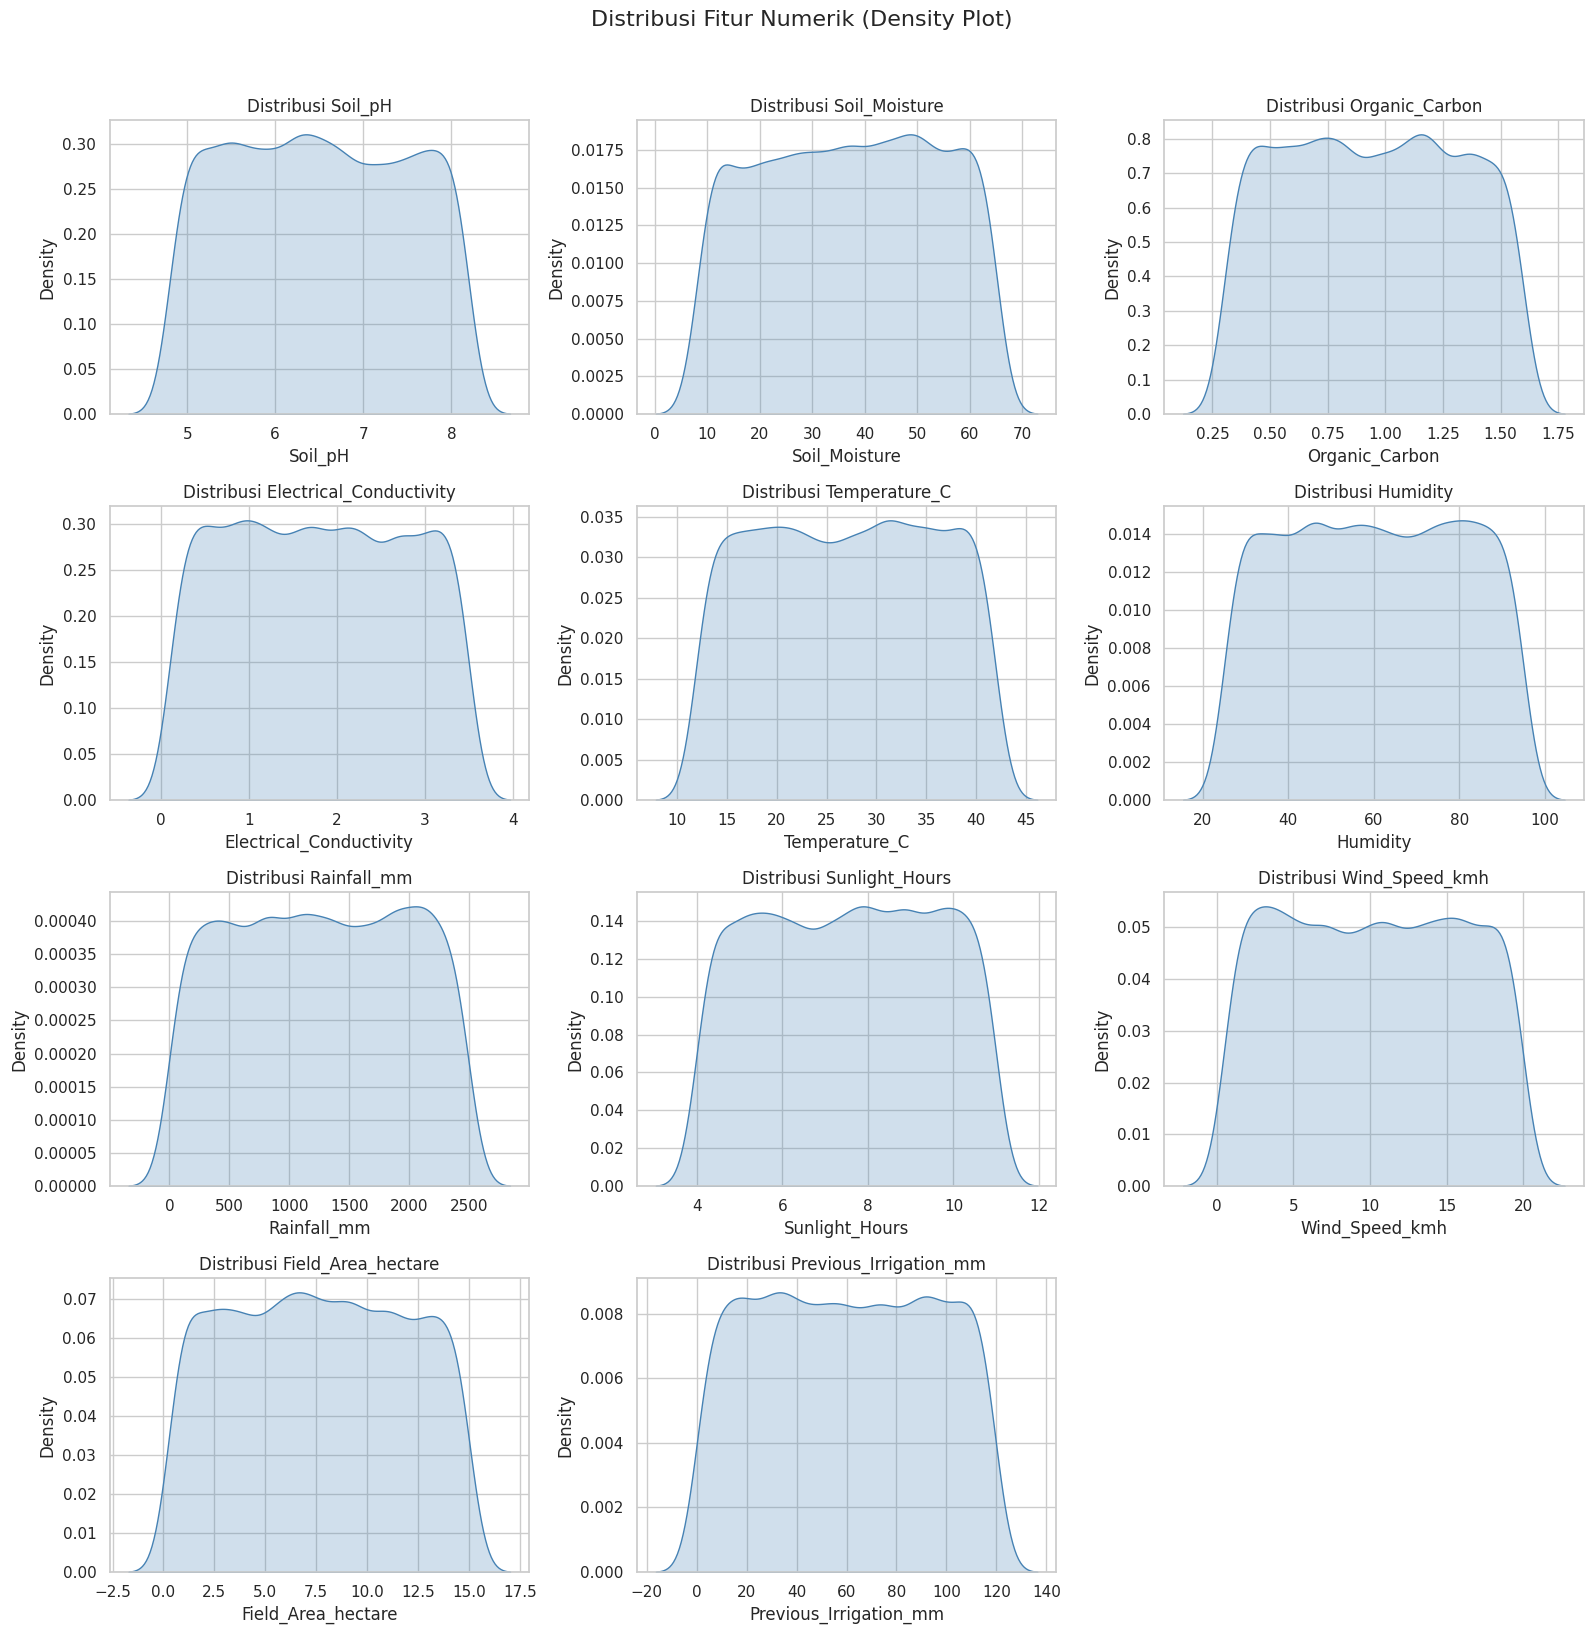

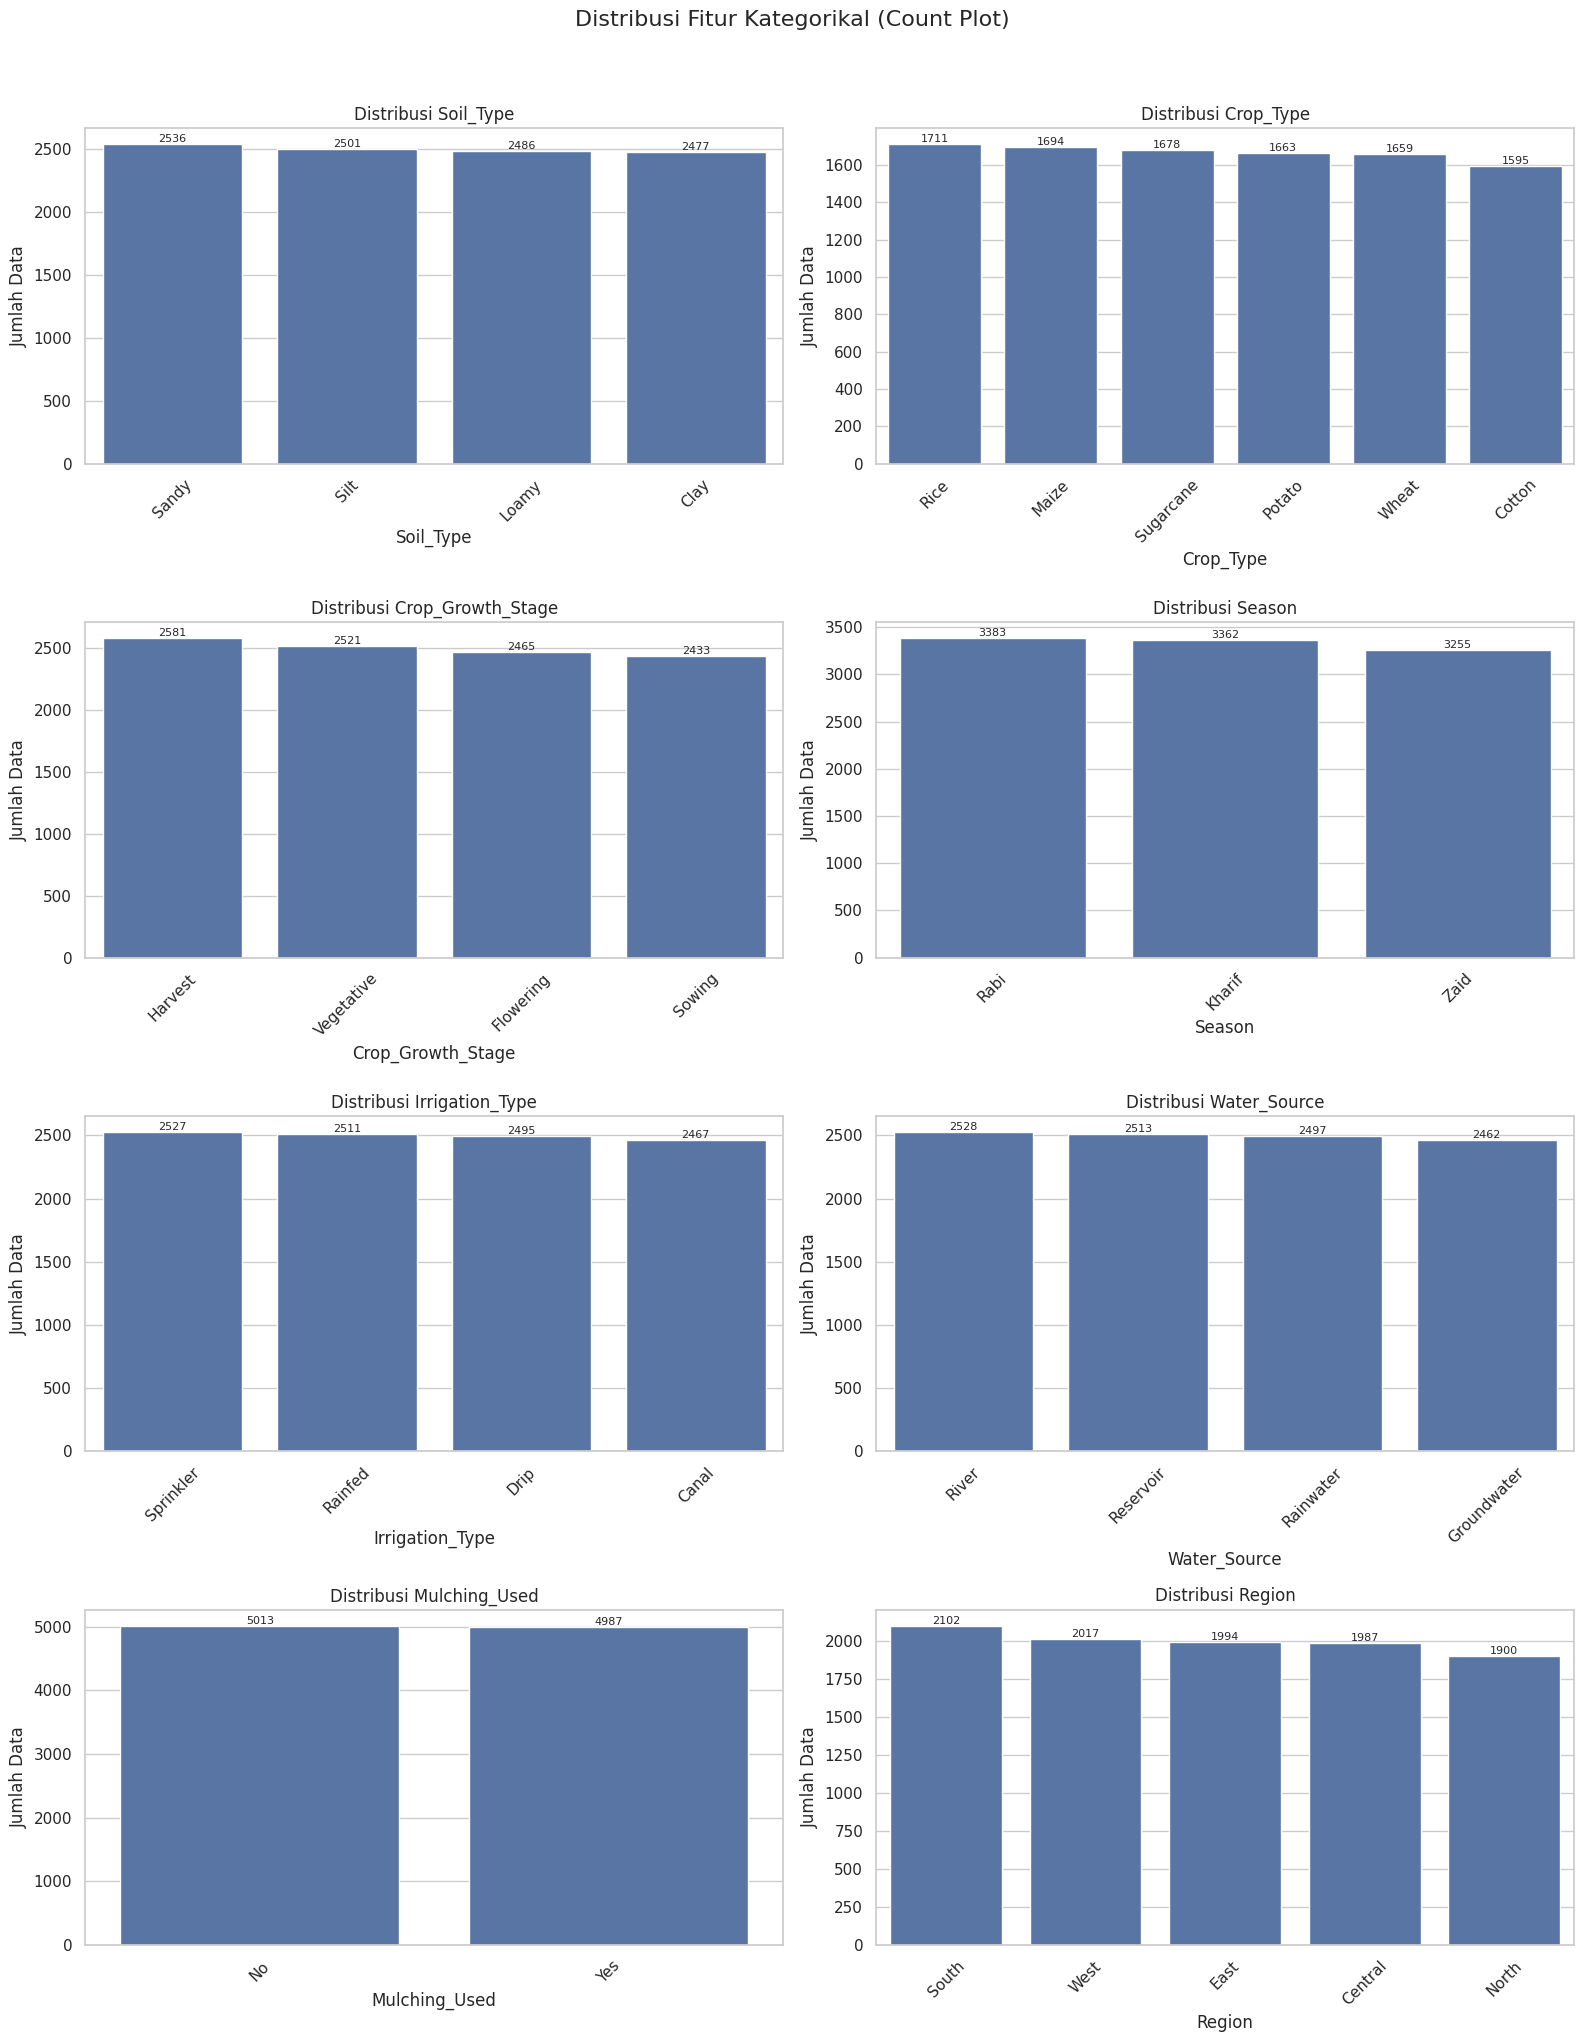

In [9]:


import math

# =========================
# 1. Identifikasi fitur
# =========================
target = "Irrigation_Need"

X = df.drop(columns=[target])

numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude="number"
).columns.tolist()

sns.set_theme(style="whitegrid")

# =========================
# 2. Distribusi fitur numerik
# Density Plot (KDE)
# =========================
n_cols = 3
n_rows = math.ceil(len(numeric_features) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4 * n_rows)
)
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    data = df[col].dropna()

    sns.kdeplot(
        data=data,
        ax=axes[i],
        fill=True,
        color="steelblue"
    )

    axes[i].set_title(f"Distribusi {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Density")

for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Distribusi Fitur Numerik (Density Plot)",
    fontsize=16,
    y=1.02
)
plt.tight_layout()
plt.show()

# =========================
# 3. Distribusi fitur kategorikal
# Count Plot
# =========================
n_cols = 2
n_rows = math.ceil(len(categorical_features) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 5 * n_rows)
)
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribusi {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Jumlah Data")
    axes[i].tick_params(axis="x", rotation=45)

    # Menampilkan jumlah pada setiap batang
    for container in axes[i].containers:
        axes[i].bar_label(container, fontsize=8)

for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Distribusi Fitur Kategorikal (Count Plot)",
    fontsize=16,
    y=1.02
)
plt.tight_layout()
plt.show()


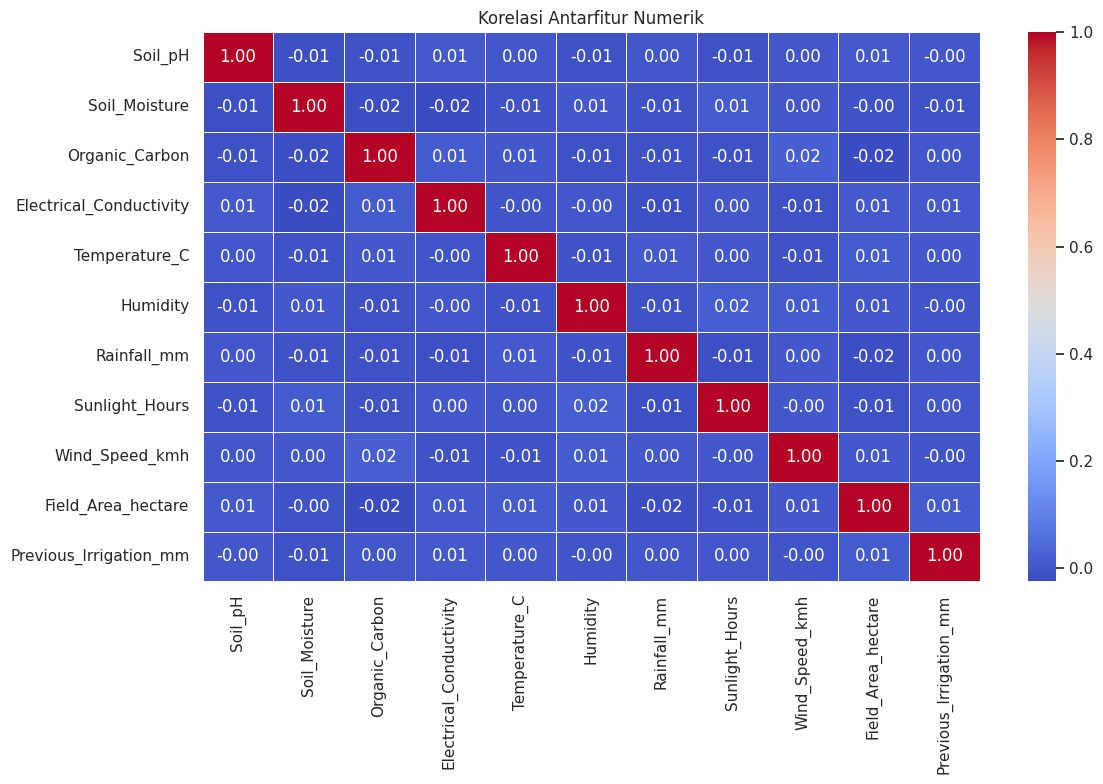

In [10]:
plt.figure(figsize=(12, 8))

corr = df[numeric_features].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Korelasi Antarfitur Numerik")
plt.tight_layout()
plt.show()

In [11]:
# 1. Pisahkan fitur dan target
X = df.drop(columns=["Irrigation_Need"])
y = df["Irrigation_Need"]

# 2. Split dataset terlebih dahulu
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

Data training: (8000, 19)
Data testing: (2000, 19)


In [13]:
# ============================================================
# 3. PREPROCESSING FITUR NUMERIK
# ============================================================
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ============================================================
# 4. PREPROCESSING FITUR KATEGORIKAL
# ============================================================
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


Melatih model: Decision Tree
Melatih model: Random Forest
Melatih model: KNN
Melatih model: Logistic Regression
Melatih model: SVM (RBF)

HASIL BASELINE MODELING


,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Decision Tree,0.9960,0.9924,0.9924,0.9924
1,Random Forest,0.9705,0.9776,0.7974,0.8476
2,SVM (RBF),0.8715,0.8901,0.6809,0.7221
3,Logistic Regression,0.8255,0.7875,0.6880,0.7220
4,KNN,0.7325,0.5467,0.5105,0.5187


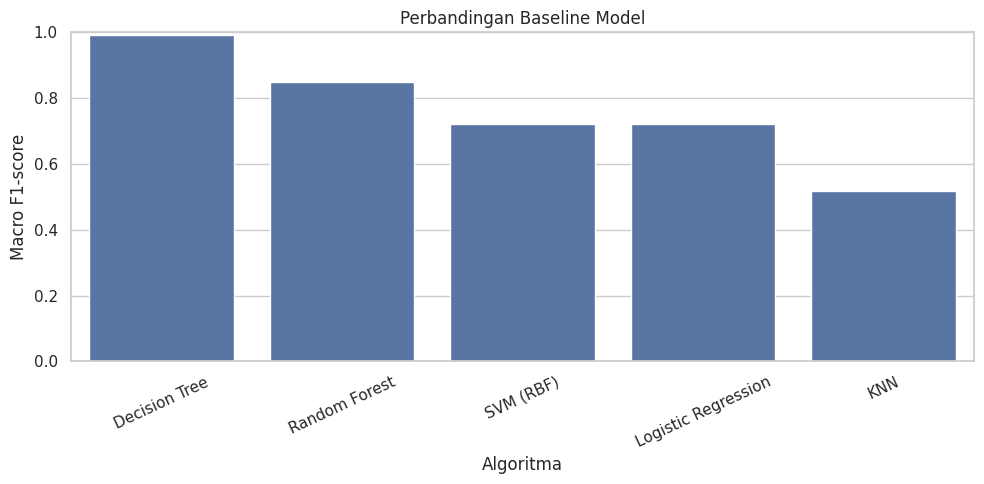


Baseline terbaik: Decision Tree

Classification Report:
              precision    recall  f1-score   support

        High       0.99      0.99      0.99        67
         Low       1.00      1.00      1.00      1173
      Medium       0.99      0.99      0.99       760

    accuracy                           1.00      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



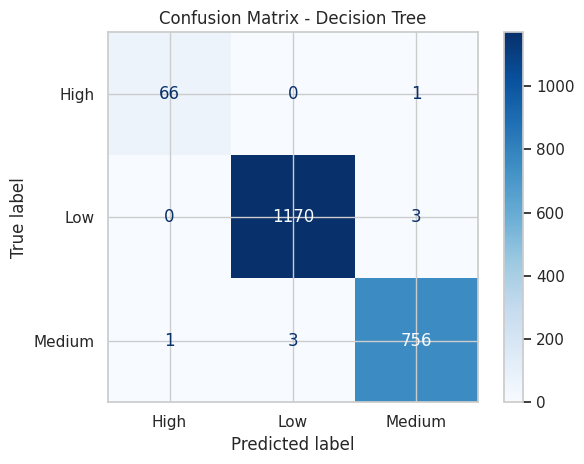

In [14]:
# ============================================================
# 5. GABUNGKAN PREPROCESSING
# ============================================================
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# ============================================================
# 6. DEFINISI MODEL BASELINE
# ============================================================
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "SVM (RBF)": SVC(
        kernel="rbf",
        random_state=42
    )
}

# ============================================================
# 7. TRAINING DAN EVALUASI
# ============================================================
results = []
trained_models = {}

for name, classifier in models.items():

    print(f"Melatih model: {name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Training dengan preprocessing
    pipeline.fit(X_train, y_train)

    # Prediksi data testing
    y_pred = pipeline.predict(X_test)

    # Simpan pipeline model
    trained_models[name] = pipeline

    # Hitung metrik evaluasi
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision Macro": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

# ============================================================
# 8. TABEL PERBANDINGAN BASELINE
# ============================================================
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Macro",
    ascending=False
).reset_index(drop=True)

print("\nHASIL BASELINE MODELING")
display(results_df.round(4))

# ============================================================
# 9. VISUALISASI PERBANDINGAN MODEL
# ============================================================
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Macro"
)

plt.title("Perbandingan Baseline Model")
plt.xlabel("Algoritma")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# ============================================================
# 10. EVALUASI BASELINE TERBAIK
# ============================================================
best_name = results_df.loc[0, "Model"]
best_baseline = trained_models[best_name]

y_pred_best = best_baseline.predict(X_test)

print("\nBaseline terbaik:", best_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

# ============================================================
# 11. CONFUSION MATRIX
# ============================================================
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

# ============================================================
# 12. SIMPAN HASIL BASELINE
# ============================================================
results_df.to_csv(
    "hasil_baseline_irigasi.csv",
    index=False
)

In [16]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Identifikasi fitur numerik dan kategorikal
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# 2. Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 3. Pipeline Decision Tree
pipeline_dt = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# 4. Ruang pencarian hyperparameter
param_grid = {
    "classifier__criterion": ["gini", "entropy", "log_loss"],
    "classifier__max_depth": [5, 10, 15, 20, 25, None],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

# 5. Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline_dt,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

# 6. Training dan pencarian parameter terbaik
grid_search.fit(X_train, y_train)

print("Hyperparameter terbaik:")
print(grid_search.best_params_)

print("\nMacro F1 terbaik pada cross-validation:")
print(round(grid_search.best_score_, 4))

# 7. Model terbaik
best_dt = grid_search.best_estimator_

Fitting 5 folds for each of 576 candidates, totalling 2880 fits
Hyperparameter terbaik:
{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5}

Macro F1 terbaik pada cross-validation:
0.9911


,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Decision Tree Tuned,0.9985,0.9987,0.9945,0.9966



Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.99      0.99        67
         Low       1.00      1.00      1.00      1173
      Medium       1.00      1.00      1.00       760

    accuracy                           1.00      2000
   macro avg       1.00      0.99      1.00      2000
weighted avg       1.00      1.00      1.00      2000



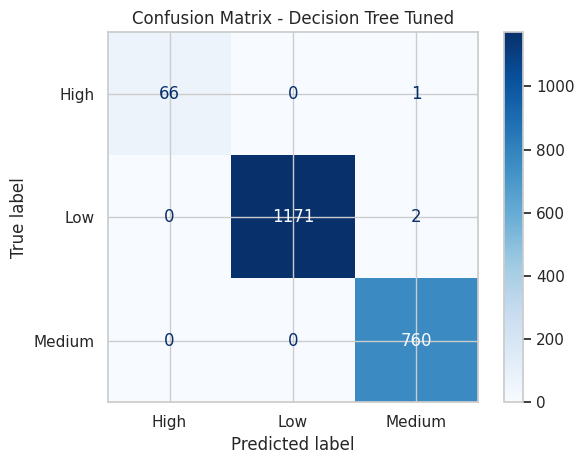

In [18]:

# Prediksi pada data test
y_pred_tuned = best_dt.predict(X_test)

# Evaluasi
hasil_tuning = pd.DataFrame([{
    "Model": "Decision Tree Tuned",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision Macro": precision_score(
        y_test, y_pred_tuned,
        average="macro", zero_division=0
    ),
    "Recall Macro": recall_score(
        y_test, y_pred_tuned,
        average="macro", zero_division=0
    ),
    "F1 Macro": f1_score(
        y_test, y_pred_tuned,
        average="macro", zero_division=0
    )
}])

display(hasil_tuning.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion Matrix - Decision Tree Tuned")
plt.tight_layout()
plt.show()


,Tahap,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Baseline,0.9960,0.9924,0.9924,0.9924
1,Hyperparameter Tuning,0.9985,0.9987,0.9945,0.9966


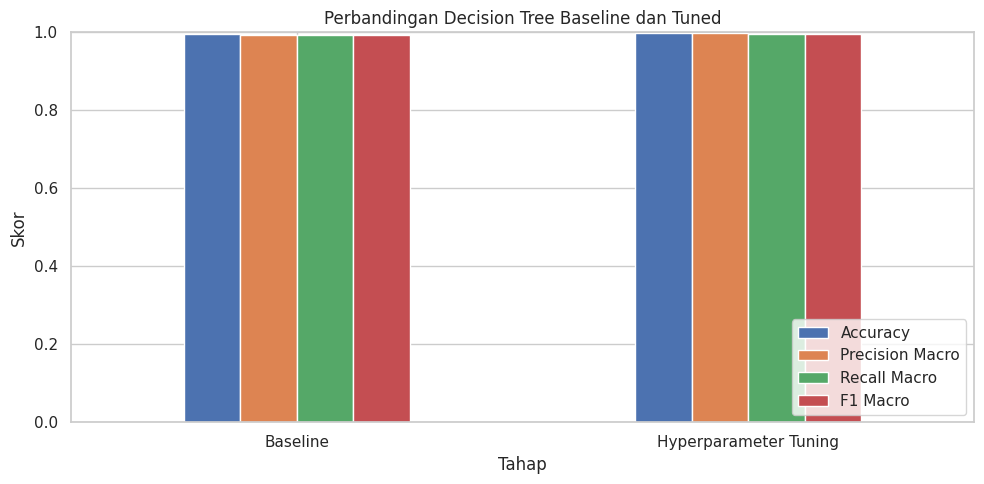

In [20]:

# Ambil hasil Decision Tree baseline
baseline_dt = results_df[
    results_df["Model"] == "Decision Tree"
].iloc[0]

perbandingan = pd.DataFrame({
    "Tahap": ["Baseline", "Hyperparameter Tuning"],
    "Accuracy": [
        baseline_dt["Accuracy"],
        hasil_tuning.loc[0, "Accuracy"]
    ],
    "Precision Macro": [
        baseline_dt["Precision Macro"],
        hasil_tuning.loc[0, "Precision Macro"]
    ],
    "Recall Macro": [
        baseline_dt["Recall Macro"],
        hasil_tuning.loc[0, "Recall Macro"]
    ],
    "F1 Macro": [
        baseline_dt["F1 Macro"],
        hasil_tuning.loc[0, "F1 Macro"]
    ]
})

display(perbandingan.round(4))

perbandingan.set_index("Tahap").plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Perbandingan Decision Tree Baseline dan Tuned")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Simpan hasil
hasil_tuning.to_csv(
    "hasil_decision_tree_tuned.csv",
    index=False
)

pd.DataFrame(grid_search.cv_results_).sort_values(
    "rank_test_score"
).to_csv(
    "hasil_grid_search_decision_tree.csv",
    index=False
)


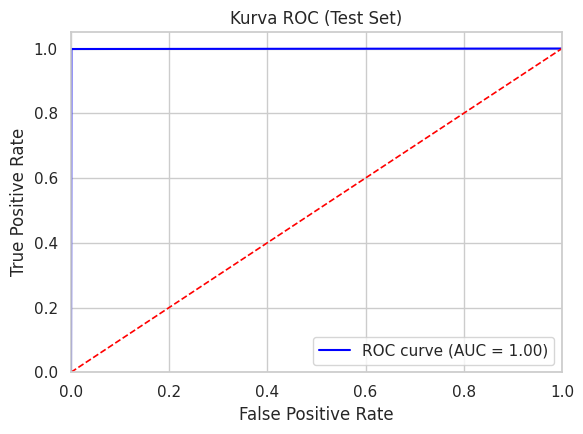

AUC (micro-average): 0.9989


In [30]:

import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Prediksi probabilitas menggunakan model terbaik tanpa SMOTENC
y_score = best_dt.predict_proba(X_test)

# Konversi target menjadi biner untuk ROC multiclass
classes = best_dt.classes_
y_test_bin = label_binarize(y_test, classes=classes)

# ROC multiclass dengan pendekatan micro-average
fpr, tpr, thresholds = roc_curve(
    y_test_bin.ravel(),
    y_score.ravel()
)

roc_auc = auc(fpr, tpr)

# Plot dengan format seperti gambar contoh
plt.figure(figsize=(6, 4.5))

plt.plot(
    fpr, tpr,
    color="blue",
    linewidth=1.5,
    label=f"ROC curve (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1], [0, 1],
    color="red",
    linestyle="--",
    linewidth=1.2
)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC (Test Set)")

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"AUC (micro-average): {roc_auc:.4f}")


,Fitur,Importance
0,num__Soil_Moisture,0.2034
1,num__Temperature_C,0.1801
2,num__Wind_Speed_kmh,0.1518
3,num__Rainfall_mm,0.1397
4,cat__Mulching_Used_No,0.1012
5,cat__Crop_Growth_Stage_Sowing,0.0893
6,cat__Crop_Growth_Stage_Harvest,0.0712
7,cat__Crop_Growth_Stage_Flowering,0.0291
8,cat__Crop_Growth_Stage_Vegetative,0.0182
9,cat__Mulching_Used_Yes,0.0157


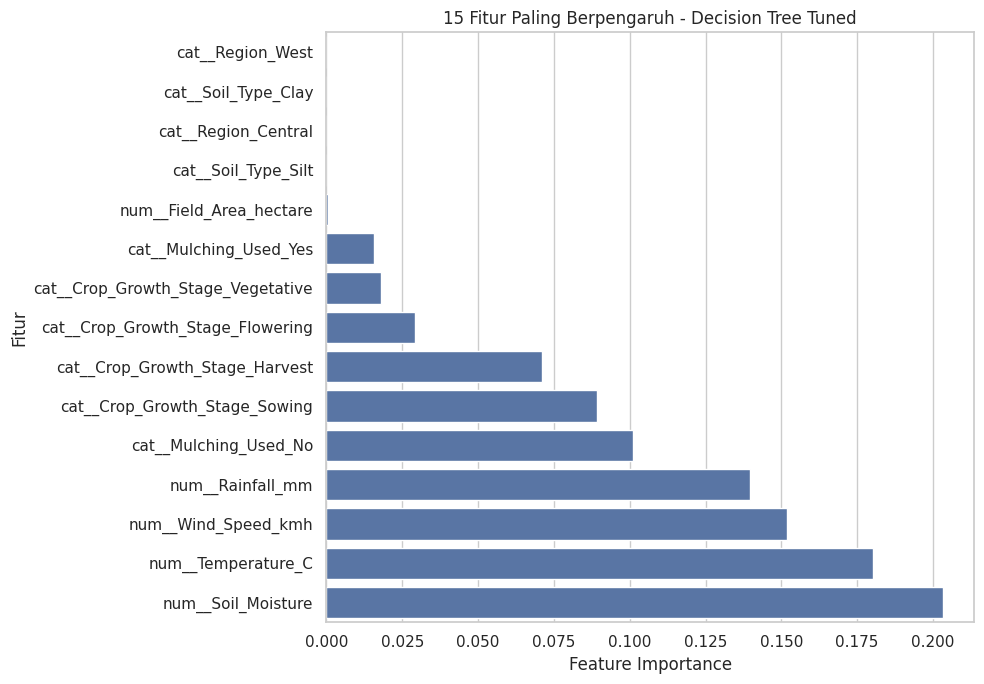

In [31]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ambil preprocessor dan model Decision Tree dari pipeline
preprocessor_fitted = best_dt.named_steps["preprocessor"]
dt_model = best_dt.named_steps["classifier"]

# Ambil nama fitur setelah preprocessing dan encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Ambil nilai feature importance
importance_values = dt_model.feature_importances_

# Buat DataFrame
feature_importance_df = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": importance_values
})

# Urutkan dari yang paling berpengaruh
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Tampilkan 15 fitur teratas
display(feature_importance_df.head(15).round(4))

# Visualisasi 15 fitur teratas
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Fitur"
)
plt.title("15 Fitur Paling Berpengaruh - Decision Tree Tuned")
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()


,Peringkat,Fitur_Asli,Importance,Kontribusi (%)
0,1,num__Soil_Moisture,0.2034,20.3353
1,2,num__Temperature_C,0.1801,18.0088
2,3,num__Wind_Speed_kmh,0.1518,15.1767
3,4,num__Rainfall_mm,0.1397,13.9715
4,5,cat__Mulching_Used_No,0.1012,10.1191
5,6,cat__Crop_Growth_Stage_Sowing,0.0893,8.9301
6,7,cat__Crop_Growth_Stage_Harvest,0.0712,7.1224
7,8,cat__Crop_Growth_Stage_Flowering,0.0291,2.9056
8,9,cat__Crop_Growth_Stage_Vegetative,0.0182,1.8158
9,10,cat__Mulching_Used_Yes,0.0157,1.5692


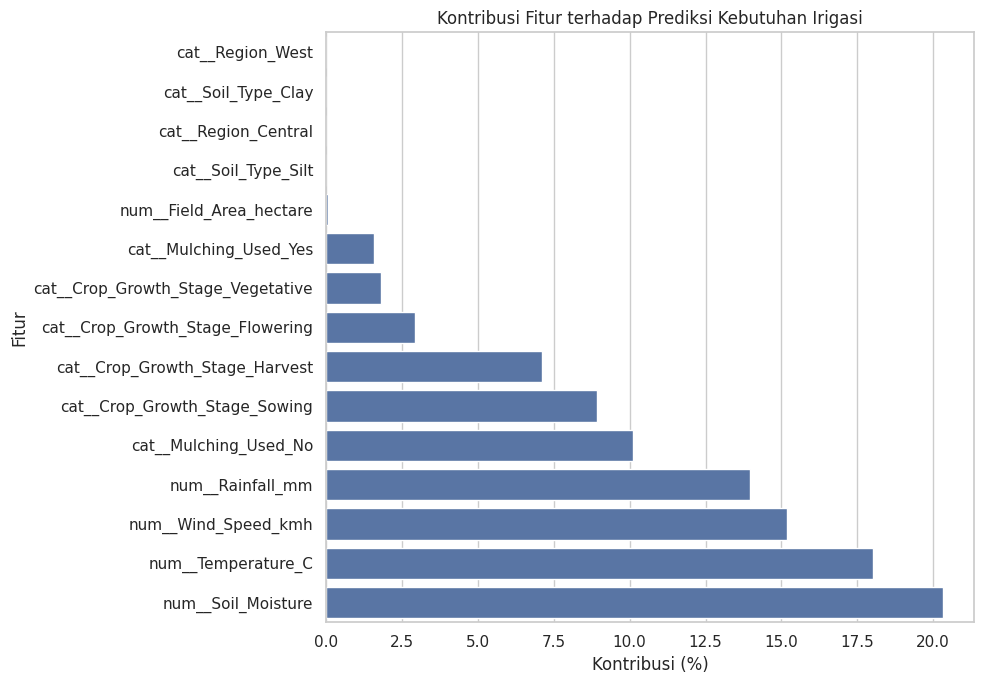

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ambil model Decision Tree hasil tuning tanpa SMOTENC
preprocessor_fitted = best_dt.named_steps["preprocessor"]
dt_model = best_dt.named_steps["classifier"]

# 2. Ambil nama fitur hasil preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# 3. Hitung feature importance
feature_importance_df = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": dt_model.feature_importances_
})

# 4. Kembalikan nama ke fitur asli
feature_importance_df["Fitur_Asli"] = (
    feature_importance_df["Fitur"]
    .str.replace(r"^(num|cat)__", "", regex=True)
    .str.split("_", n=1)
    .str[0]
)

# Gunakan nama fitur asli dari dataset agar kategori
# seperti Soil_Type_Clay tetap dikelompokkan ke Soil_Type
original_features = X_train.columns.tolist()

def identify_original_feature(encoded_name):
    for feature in sorted(original_features, key=len, reverse=True):
        if encoded_name == feature or encoded_name.startswith(feature + "_"):
            return feature
    return encoded_name

feature_importance_df["Fitur_Asli"] = (
    feature_importance_df["Fitur"]
    .apply(identify_original_feature)
)

# 5. Gabungkan importance untuk setiap fitur asli
importance_grouped = (
    feature_importance_df
    .groupby("Fitur_Asli", as_index=False)["Importance"]
    .sum()
)

# 6. Hitung kontribusi relatif dalam persen
total_importance = importance_grouped["Importance"].sum()

if total_importance > 0:
    importance_grouped["Kontribusi (%)"] = (
        importance_grouped["Importance"] / total_importance * 100
    )
else:
    importance_grouped["Kontribusi (%)"] = 0.0

# 7. Urutkan dan tambahkan peringkat
importance_grouped = importance_grouped.sort_values(
    "Kontribusi (%)", ascending=False
).reset_index(drop=True)

importance_grouped.insert(
    0, "Peringkat", range(1, len(importance_grouped) + 1)
)

# 8. Tampilkan tabel
display(
    importance_grouped[
        ["Peringkat", "Fitur_Asli", "Importance", "Kontribusi (%)"]
    ].round(4)
)

# 9. Visualisasi kontribusi fitur
top_features = importance_grouped.head(15).sort_values(
    "Kontribusi (%)", ascending=True
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features,
    x="Kontribusi (%)",
    y="Fitur_Asli"
)
plt.title("Kontribusi Fitur terhadap Prediksi Kebutuhan Irigasi")
plt.xlabel("Kontribusi (%)")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

# 10. Simpan hasil
importance_grouped.to_csv(
    "kontribusi_fitur_decision_tree.csv",
    index=False
)


In [34]:

import joblib
import json
import pandas as pd
from google.colab import files

# Simpan model terbaik
joblib.dump(best_dt, "model_irigasi_tuned.pkl")

# Simpan metadata fitur berdasarkan X_train
metadata = {
    "feature_order": X_train.columns.tolist(),
    "numeric_features": X_train.select_dtypes(
        include="number"
    ).columns.tolist(),
    "categorical_features": X_train.select_dtypes(
        exclude="number"
    ).columns.tolist(),
    "numeric_info": {},
    "categorical_options": {},
    "classes": [str(c) for c in best_dt.classes_]
}

for col in metadata["numeric_features"]:
    s = pd.to_numeric(X_train[col], errors="coerce")
    metadata["numeric_info"][col] = {
        "min": float(s.min()),
        "max": float(s.max()),
        "median": float(s.median())
    }

for col in metadata["categorical_features"]:
    metadata["categorical_options"][col] = sorted(
        X_train[col].dropna().astype(str).unique().tolist()
    )

with open("metadata_irigasi.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print("File model dan metadata berhasil dibuat.")


File model dan metadata berhasil dibuat.


In [35]:

files.download("model_irigasi_tuned.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

from google.colab import files

files.download("model_irigasi_tuned.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:

files.download("metadata_irigasi.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import sklearn
print(sklearn.__version__)

1.6.1
